# Rating de los jugadores: el elo de cada uno en cada partida

### League of Legends, LAS. Sección aparte del EDA, con su propio análisis

Riot no da el rango de un jugador **al momento de cada partida**: las partidas no
traen el rango de los participantes y la API de ligas solo da el rango actual. Lo
único que tenemos es **una foto del padrón** (tabla `players`, 04/09/2026) con el
LP, las victorias y las derrotas de cada jugador Diamond+ ese día. Esta sección
estima la habilidad de cada jugador en cada partida con un **sistema de rating**
que aprende de los resultados (`src/features/rating.py`, `PROJECT_SUMMARY.md` §9.S.21):

* **TrueSkill de equipos.** La habilidad de cada jugador es una normal
  $N(\mu, \sigma^2)$; la del equipo es la suma. Después de cada partida, los
  ganadores suben y los perdedores bajan, más cuanto más sorprendente fue el
  resultado y cuanto más incierto era cada uno.
* **Escala en LP absolutos.** Diamond IV 0 LP = 0, cada división suma 100, Master 0
  LP = 400 (Master, Grandmaster y Challenger comparten una escala). $\mu$ puede ser
  negativa: un Emerald que cae en una partida Diamond.
* **Partidas que no vimos.** Antes de la foto tenemos solo una parte de las partidas
  de cada jugador. La incertidumbre crece entre dos partidas observadas según cuántas
  jugó en el medio sin que las viéramos (su cobertura frente a las W + L de la foto).
* **La foto como medición.** El 04/09, el LP de la foto corrige a cada jugador del
  padrón como un filtro de Kalman. Ninguna partida usa la foto antes de su fecha.
* **Sin fuga del target.** Cada fila tiene el rating **previo** a la partida: no
  depende de su resultado.

> **Estado: sin evaluar.** El rating se evalúa recién con la recorrida de la foto
> del 04/09 a una **segunda foto**: todos los jugadores del padrón arrancan con su LP
> real y se recorren las partidas posteriores, donde la cobertura es casi completa.
> La segunda foto da la pérdida. Hasta entonces esta sección describe los datos que
> sostienen el rating (secciones 1 a 4). Ver `PROJECT_SUMMARY.md` §9.S.21.

**Qué datos se miran.** Las descripciones de la foto y de la cobertura usan todo el
dataset, porque no involucran resultados. Lo que involucra resultados (sección 3)
usa solo partidas anteriores a la foto, que son del train: el test no se mira.

1. La foto del padrón.
2. Cobertura: cuántas de sus partidas tenemos.
3. ¿Vemos más victorias o más derrotas de las reales?
4. La foto envejece: filas sin tier en el tiempo.
5. Pendiente: evaluación con la segunda foto.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for p in (ROOT, ROOT / "scripts" / "analysis"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.features.rating import ParametrosRating, correr, MASTER_BASE  # noqa: E402
from build_rating import (INICIO_SPLIT, MIN_PREVIAS_VALIDACION, VAL_DESDE, cargar_foto,  # noqa: E402
                          cargar_partes, ms)

DATA_DIR = ROOT / "data"
TZ = "America/Argentina/Buenos_Aires"
TIER_ORDER = ["CHALLENGER", "GRANDMASTER", "MASTER", "DIAMOND"]
TIER_COLORS = {"CHALLENGER": "#F0B232", "GRANDMASTER": "#C8282E", "MASTER": "#9B4FD1", "DIAMOND": "#86b6ef"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "legend.frameon": False, "figure.dpi": 110,
})

partes = cargar_partes()
foto, T_FOTO = cargar_foto(ROOT / "data" / "lol_las.db")
splits = pd.read_csv(DATA_DIR / "splits" / "match_split.csv", usecols=["match_id", "split", "tier"])
manifest = json.loads((DATA_DIR / "splits" / "split_manifest.json").read_text(encoding="utf-8"))
CORTE_MS = ms(manifest["corte"])
info = json.loads((DATA_DIR / "analysis" / "rating_params.json").read_text(encoding="utf-8"))
PARAMS = ParametrosRating(**info["elegidos"])
rating = pd.read_csv(DATA_DIR / "rating_partida.csv")

partes = partes.merge(splits[["match_id", "split"]], on="match_id", how="left")
rating = rating.merge(partes[["match_id", "player_id", "team_id", "win", "game_creation", "split"]],
                      on=["match_id", "player_id"])
train = rating[rating["split"] == "train"]
fecha = lambda t: pd.to_datetime(t, unit="ms", utc=True).dt.tz_convert(TZ)  # noqa: E731
print(f"Partidas de LAS: {partes['match_id'].nunique():,} | filas con rating: {len(rating):,} "
      f"| del train: {train['match_id'].nunique():,} partidas")
print(f"Foto del padrón: {len(foto):,} jugadores, {pd.Timestamp(T_FOTO, unit='ms', tz='UTC').tz_convert(TZ):%d/%m/%Y %H:%M} ART")
print("Parámetros elegidos:", {k: round(v, 1) for k, v in info["elegidos"].items()})

Partidas de LAS: 272,521 | filas con rating: 2,725,210 | del train: 192,104 partidas
Foto del padrón: 40,821 jugadores, 04/09/2026 19:51 ART
Parámetros elegidos: {'beta': 1600.0, 'tau': 5.0, 'sigma0': 400.0, 'sigma_foto': 800.0, 'mu0': 0.0, 'ventaja_roja': 228.2, 'max_ocultas': 30.0}


## 1. La foto del padrón

LP absoluto de cada jugador del padrón el día de la foto. En Master+ el LP no tiene
techo: Grandmaster y Challenger no son un LP fijo sino los mejores puestos del
ladder (500 y 200 jugadores), así que sus cortes salen de la foto.

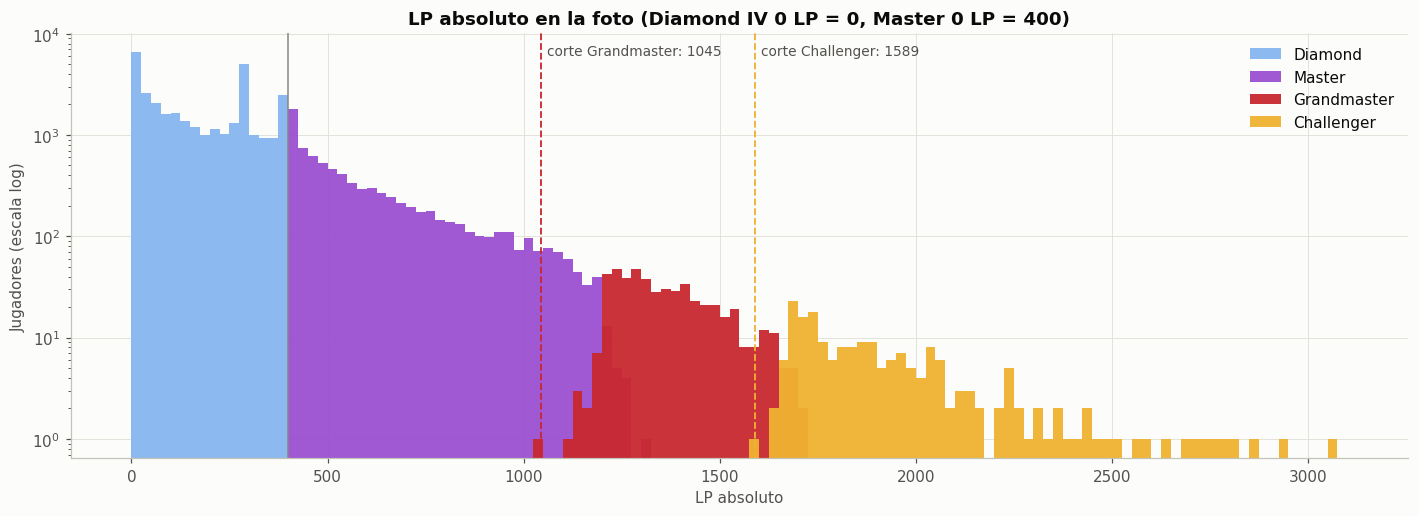

,count,min,50%,max
tier,,,,
CHALLENGER,200.0,1589.0,1860.0,3074.0
GRANDMASTER,500.0,1045.0,1345.0,1708.0
MASTER,8297.0,400.0,524.0,1318.0
DIAMOND,31824.0,0.0,152.0,399.0


In [2]:
fig, ax = plt.subplots(figsize=(13, 4.8))
bins = np.arange(0, foto["z"].max() + 50, 25)
for t in TIER_ORDER[::-1]:
    ax.hist(foto.loc[foto["tier"] == t, "z"], bins=bins, color=TIER_COLORS[t], label=t.capitalize(), alpha=0.95)
for t in ["GRANDMASTER", "CHALLENGER"]:
    corte = foto.loc[foto["tier"] == t, "z"].min()
    ax.axvline(corte, color=TIER_COLORS[t], linestyle="--", linewidth=1.2)
    ax.annotate(f"corte {t.capitalize()}: {corte:.0f}", xy=(corte, ax.get_ylim()[1] * 0.9), xytext=(4, 0),
                textcoords="offset points", fontsize=9, color=INK_2)
ax.axvline(MASTER_BASE, color=MUTED, linewidth=1)
ax.set_yscale("log")
ax.set_title("LP absoluto en la foto (Diamond IV 0 LP = 0, Master 0 LP = 400)")
ax.set_xlabel("LP absoluto")
ax.set_ylabel("Jugadores (escala log)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
display(foto.groupby("tier")["z"].describe()[["count", "min", "50%", "max"]].reindex(TIER_ORDER).round(0))

## 2. Cobertura: cuántas de sus partidas tenemos

La foto dice cuántas partidas jugó cada uno en el split ($W + L$). Las comparamos con
las que tenemos entre el inicio del split y la foto. **Supuesto:** el split empezó el
`INICIO_SPLIT` (la fecha exacta no está confirmada). Una cobertura baja significa que
entre dos partidas observadas el jugador jugó muchas que no vimos, y el rating lo
refleja agrandando su incertidumbre.

Cobertura = partidas observadas desde el 2026-01-08 hasta la foto / (W + L) de la foto, en %:


,jugadores,sin_partidas,p25,mediana,p75
tier,,,,,
CHALLENGER,200,0.0,47.8,56.8,70.5
GRANDMASTER,500,0.0,35.2,43.3,55.6
MASTER,8297,0.0,17.2,26.1,38.1
DIAMOND,31824,21.0,0.5,2.7,8.1


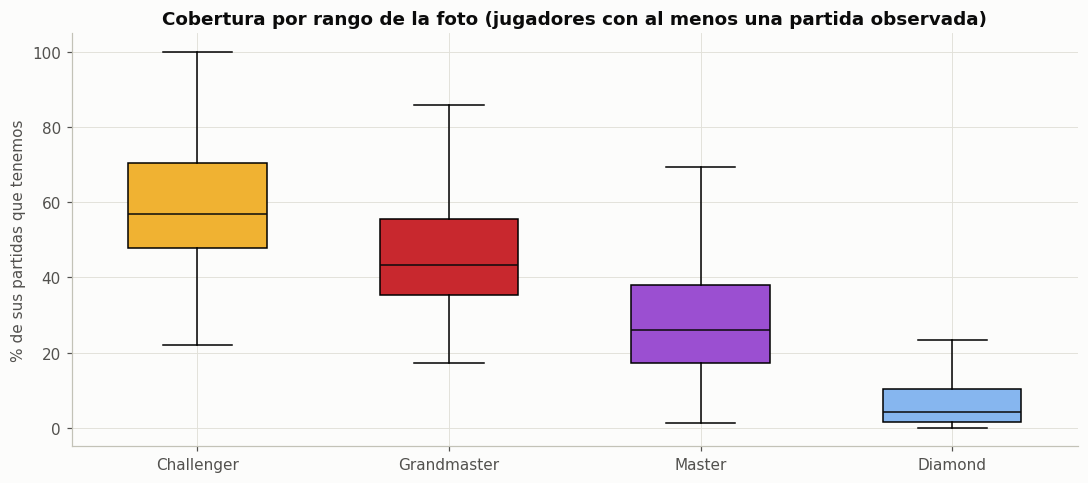

In [3]:
obs = (partes[(partes["game_creation"] >= ms(INICIO_SPLIT)) & (partes["game_creation"] < T_FOTO)]
       .groupby("player_id").size().rename("observadas"))
cob = foto.join(obs, on="player_id").fillna({"observadas": 0})
cob["cobertura"] = (cob["observadas"] / cob["partidas"].clip(lower=1)).clip(upper=1.5)
tabla = cob.groupby("tier").agg(jugadores=("cobertura", "size"),
                                 sin_partidas=("observadas", lambda s: 100 * (s == 0).mean()),
                                 p25=("cobertura", lambda s: 100 * s.quantile(0.25)),
                                 mediana=("cobertura", lambda s: 100 * s.median()),
                                 p75=("cobertura", lambda s: 100 * s.quantile(0.75))).reindex(TIER_ORDER)
print(f"Cobertura = partidas observadas desde el {INICIO_SPLIT} hasta la foto / (W + L) de la foto, en %:")
display(tabla.round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))
datos = [cob.loc[(cob["tier"] == t) & (cob["observadas"] > 0), "cobertura"] * 100 for t in TIER_ORDER]
caja = ax.boxplot(datos, patch_artist=True, showfliers=False, widths=0.55, medianprops=dict(color=INK))
for patch, t in zip(caja["boxes"], TIER_ORDER):
    patch.set_facecolor(TIER_COLORS[t])
ax.set_xticks(range(1, 5), [t.capitalize() for t in TIER_ORDER])
ax.set_ylabel("% de sus partidas que tenemos")
ax.set_title("Cobertura por rango de la foto (jugadores con al menos una partida observada)")
plt.tight_layout()
plt.show()

## 3. ¿Vemos más victorias o más derrotas de las reales?

Si nuestra recolección viera más victorias que derrotas (o al revés), el rating
aprendido de nuestras partidas estaría sesgado. Para cada jugador con al menos
`MIN_OBS` partidas observadas:

$$z = \frac{WR_{obs} - WR_{foto}}{\sqrt{WR_{foto}(1 - WR_{foto})/n}}$$

Sin sesgo, $z$ se reparte como una normal estándar. (Es aproximado: las partidas
observadas son parte de las que cuenta la foto, así que $z$ queda algo más angosta.)

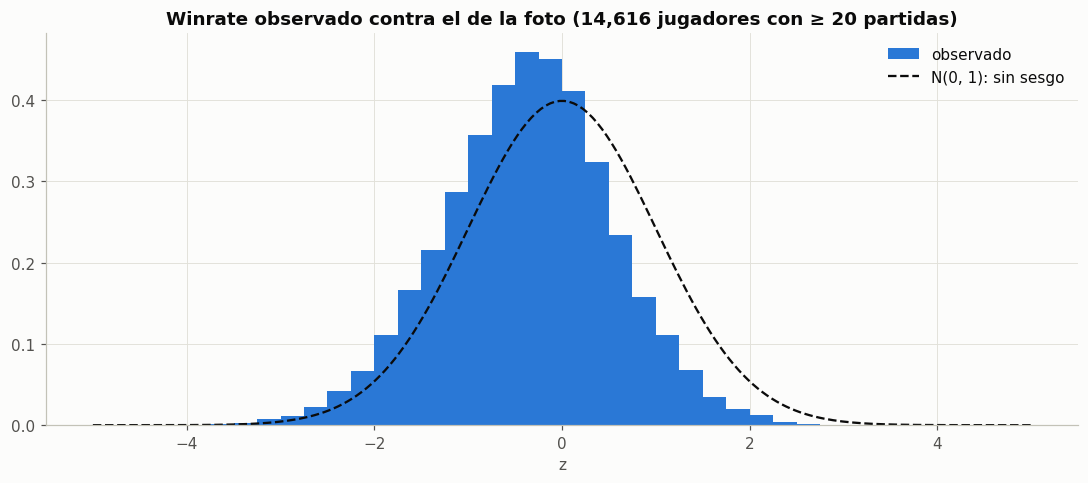

,size,mean,std
tier,,,
CHALLENGER,200,-0.202,0.736
GRANDMASTER,500,-0.141,0.761
MASTER,8116,-0.185,0.847
DIAMOND,5800,-0.646,0.934


In [4]:
MIN_OBS = 20
pre = partes[(partes["game_creation"] >= ms(INICIO_SPLIT)) & (partes["game_creation"] < T_FOTO)]
wr_obs = pre.groupby("player_id")["win"].agg(["mean", "size"])
sql_wins = foto.set_index("player_id")
x = wr_obs.join(sql_wins[["tier", "partidas"]], how="inner")
import sqlite3
con = sqlite3.connect(f"file:{(DATA_DIR / 'lol_las.db').resolve()}?mode=ro", uri=True)
w = pd.read_sql_query("SELECT m.player_id, MAX(p.wins) AS wins FROM players p JOIN player_id_map m "
                      "ON m.puuid = p.puuid GROUP BY m.player_id", con).set_index("player_id")["wins"]
con.close()
x = x.join(w)
x = x[(x["size"] >= MIN_OBS) & (x["partidas"] > 0)]
x["wr_foto"] = x["wins"] / x["partidas"]
x["z"] = (x["mean"] - x["wr_foto"]) / np.sqrt(x["wr_foto"] * (1 - x["wr_foto"]) / x["size"])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(x["z"].clip(-5, 5), bins=np.arange(-5, 5.25, 0.25), density=True, color=CATEGORICAL[0], label="observado")
xs = np.linspace(-5, 5, 200)
ax.plot(xs, norm.pdf(xs), color=INK, linestyle="--", label="N(0, 1): sin sesgo")
ax.set_title(f"Winrate observado contra el de la foto ({len(x):,} jugadores con ≥ {MIN_OBS} partidas)")
ax.set_xlabel("z")
ax.legend()
plt.tight_layout()
plt.show()
display(x.groupby("tier")["z"].agg(["size", "mean", "std"]).reindex(TIER_ORDER).round(3))

## 4. La foto envejece: filas sin tier en el tiempo

El tier de cada fila del dataset sale solo de la foto del 04/09. Un jugador que no
estaba en el padrón ese día (Emerald en partidas Diamond, quien subió después,
cuentas nuevas) queda sin tier, y cuanto más lejos de la foto, más pasa. Esta es la
motivación del rating: una foto sola no alcanza para el período del test. (Este
gráfico no usa resultados.)

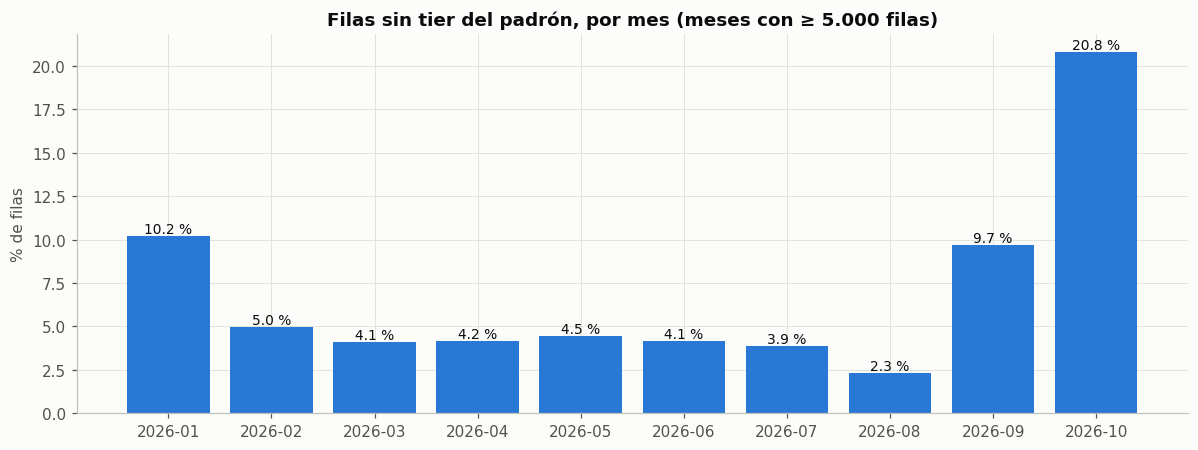

In [5]:
full_tier = pd.read_csv(DATA_DIR / "full_dataset.csv", usecols=["match_id", "player_tier", "game_creation"])
full_tier = full_tier[full_tier["match_id"].str.startswith("LA2_")]
full_tier["mes"] = fecha(full_tier["game_creation"]).dt.tz_localize(None).dt.to_period("M")
por_mes = full_tier.groupby("mes").agg(filas=("player_tier", "size"),
                                       sin_tier=("player_tier", lambda s: 100 * s.isna().mean()))
por_mes = por_mes[por_mes["filas"] >= 5000]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(por_mes.index.astype(str), por_mes["sin_tier"], color=CATEGORICAL[0])
for i, v in enumerate(por_mes["sin_tier"]):
    ax.text(i, v, f"{v:.1f} %", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Filas sin tier del padrón, por mes (meses con ≥ 5.000 filas)")
ax.set_ylabel("% de filas")
plt.tight_layout()
plt.show()

## 5. Pendiente: evaluación con la segunda foto

**Por qué no se evalúa todavía.** Un sistema de rating solo mide habilidad
*relativa* a los rivales: si todos arrancan en el mismo valor, un grupo de
Challengers que juega entre sí no tiene forma de llegar a 2.400 LP. Evaluarlo antes
de la foto mide sobre todo esa falta de ancla. Además, elegir los parámetros por
cómo predicen partidas no sirve para el elo: la configuración que mejor predice
(log-loss 0,6919 contra 0,6926 de una constante) ordena a los jugadores peor contra
la foto que los parámetros por defecto (Spearman 0,45 contra 0,58).

**Cómo se va a evaluar.**

1. Se arranca en la foto del 04/09: cada jugador del padrón con su LP real.
2. Se recorren las partidas posteriores, actualizando el rating con cada una.
3. En la fecha de la segunda foto, se compara el rating de cada jugador con su LP
   real. Esa es la pérdida para ajustar $eta$, $	au$ y $\sigma_0$, y para medir
   cómo crece el error con la distancia en días.

La segunda foto es posterior al test, así que sus W/L incluyen resultados del test:
sirve para evaluar el rating, **no** para ajustar nada que alimente al modelo de
draft. Las secciones de evaluación ya escritas (ajuste, calibración, trayectorias)
se generan con `python scripts/analysis/build_rating_nb.py --evaluacion`.